In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('imdb_data_cleaned.csv')

print("Розмірність даних:", df.shape)
df.head() 

Matplotlib is building the font cache; this may take a moment.


Розмірність даних: (10000, 13)


,showid,title,type,releaseyear,endyear,duration,genres,cast,imdbrating,numvotes,popularityrank,isadult,url
0,tt0111161,The Shawshank Redemption,Movie,1994,1994,142 min,Drama,"Tim Robbins, Morgan Freeman, Bob Gunton, Willi...",9.3,3175959,1,0,https://www.imdb.com/title/tt0111161/
1,tt0468569,The Dark Knight,Movie,2008,2008,152 min,"Action,Crime,Drama","Christian Bale, Heath Ledger, Aaron Eckhart, M...",9.1,3155324,2,0,https://www.imdb.com/title/tt0468569/
2,tt1375666,Inception,Movie,2010,2010,148 min,"Action,Adventure,Sci-Fi","Leonardo DiCaprio, Joseph Gordon-Levitt, Ellio...",8.8,2804960,3,0,https://www.imdb.com/title/tt1375666/
3,tt0944947,Game of Thrones,TV Show,2011,2019,60 min,"Action,Adventure,Drama","Emilia Clarke, Peter Dinklage, Kit Harington, ...",9.2,2602061,4,0,https://www.imdb.com/title/tt0944947/
4,tt0903747,Breaking Bad,TV Show,2008,2013,48 min,"Crime,Drama,Thriller","Bryan Cranston, Aaron Paul, Anna Gunn, Betsy B...",9.5,2596925,5,0,https://www.imdb.com/title/tt0903747/


In [2]:
print("--- Кількість пропусків у колонках ---")
print(df.isnull().sum())

if 'rating' in df.columns:
    df = df.dropna(subset=['rating'])
elif 'IMDb Rating' in df.columns:
    df = df.dropna(subset=['IMDb Rating'])

df = df.drop_duplicates()

print("\nРозмірність після очищення:", df.shape)

--- Кількість пропусків у колонках ---
showid             0
title              0
type               0
releaseyear        0
endyear            0
duration           0
genres             1
cast              46
imdbrating         0
numvotes           0
popularityrank     0
isadult            0
url                0
dtype: int64

Розмірність після очищення: (10000, 13)


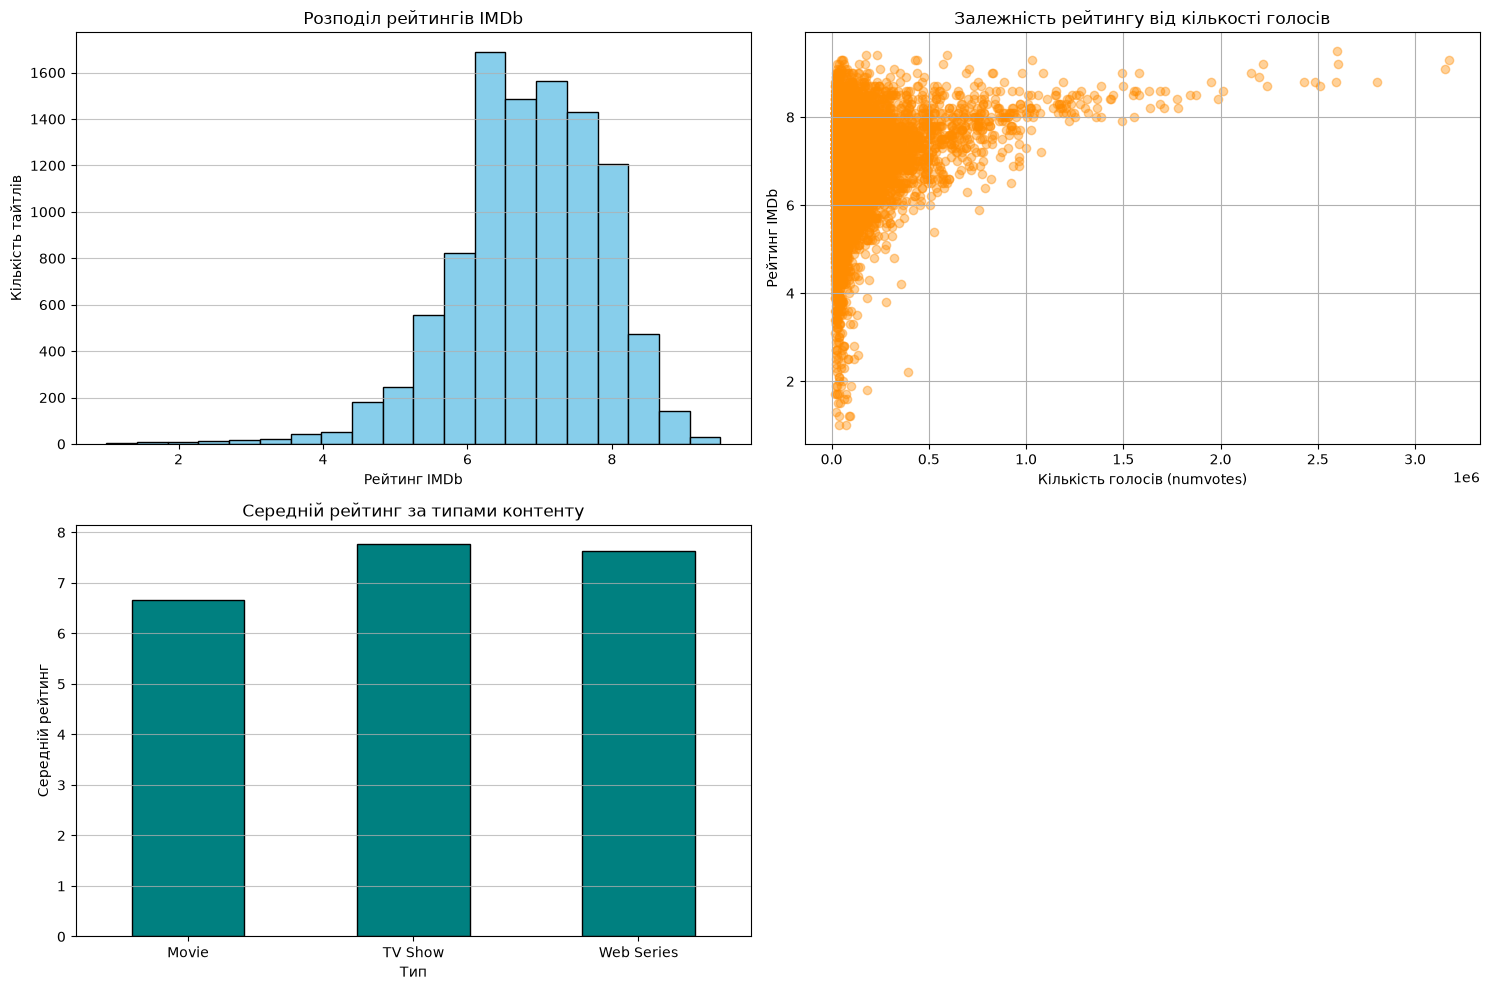

In [3]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.hist(df['imdbrating'], bins=20, color='skyblue', edgecolor='black')
plt.title('Розподіл рейтингів IMDb')
plt.xlabel('Рейтинг IMDb')
plt.ylabel('Кількість тайтлів')
plt.grid(axis='y', alpha=0.75)

plt.subplot(2, 2, 2)
plt.scatter(df['numvotes'], df['imdbrating'], alpha=0.4, color='darkorange')
plt.title('Залежність рейтингу від кількості голосів')
plt.xlabel('Кількість голосів (numvotes)')
plt.ylabel('Рейтинг IMDb')
plt.grid(True)

plt.subplot(2, 2, 3)
type_ratings = df.groupby('type')['imdbrating'].mean()
type_ratings.plot(kind='bar', color='teal', edgecolor='black')
plt.title('Середній рейтинг за типами контенту')
plt.xlabel('Тип')
plt.ylabel('Середній рейтинг')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.show()

In [4]:
numeric_cols = df.select_dtypes(include=['int64', 'float64'])
print("--- Матриця кореляції числових показників ---")
print(numeric_cols.corr())

--- Матриця кореляції числових показників ---
                releaseyear  imdbrating  numvotes  popularityrank  isadult
releaseyear        1.000000   -0.172687  0.008496       -0.039331      NaN
imdbrating        -0.172687    1.000000  0.258350       -0.183596      NaN
numvotes           0.008496    0.258350  1.000000       -0.619921      NaN
popularityrank    -0.039331   -0.183596 -0.619921        1.000000      NaN
isadult                 NaN         NaN       NaN             NaN      NaN


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

features = ['numvotes', 'popularityrank', 'releaseyear']
X = df[features]
y = df['imdbrating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

print("--- Результати оцінки моделей ---")
print(f"Linear Regression R2: {r2_score(y_test, lr_preds):.4f} | MAE: {mean_absolute_error(y_test, lr_preds):.4f}")
print(f"Random Forest     R2: {r2_score(y_test, rf_preds):.4f} | MAE: {mean_absolute_error(y_test, rf_preds):.4f}")

--- Результати оцінки моделей ---
Linear Regression R2: 0.1088 | MAE: 0.7484
Random Forest     R2: -0.0717 | MAE: 0.8171


## Висновки проєкту
1. **Аналіз даних (EDA):** Більшість рейтингів IMDb знаходяться в діапазоні від 6.0 до 8.0. Виявлено позитивну кореляцію між кількістю голосів (`numvotes`) та рейтингом.
2. **Машинне навчання:** Модель Linear Regression показала MAE ≈ 0.75, що дозволяє прогнозувати рейтинг фільму з середньою похибкою менше ніж 1 бал на основі популярності та року випуску.